# Día 2 · Recolección y descripción de los datos

**Apartado del documento que cubre este día:** 3 (Recolección y descripción de datos).

**Al terminar este día, cada integrante del equipo debe poder explicar sin leer:**
1. De dónde salieron los datos y cómo se revisaron.
2. Qué diferencia hay entre una variable cuantitativa y una cualitativa.
3. Qué significa cada medida: media, mediana, desviación estándar, mínimo, máximo y rango.
4. Por qué en el saldo la mediana es mayor que la media.
5. Qué información aporta cada gráfica del proyecto.

Apoyo opcional: `clase_01_dispersion.ipynb` explica la desviación estándar desde cero.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

RAIZ = Path.cwd().parent if Path.cwd().name == "clases" else Path.cwd()
poblacion = pd.read_csv(RAIZ / "data" / "processed" / "poblacion_clientes.csv")
muestra = pd.read_csv(RAIZ / "data" / "processed" / "muestra_clientes_n1000.csv")
N = len(poblacion)
n = len(muestra)
print("Clientes en la población (N):", N)
print("Clientes en la muestra (n):", n)

Clientes en la población (N): 10000
Clientes en la muestra (n): 1000


---
## Paso 1 · Qué pide el documento

El documento pide:
- Explicar **cómo se obtuvieron los datos** (menciona como opciones formularios, Excel, Python, registros, bases de datos).
- Para **variables cuantitativas**, como mínimo: media, mediana, desviación estándar, mínimo, máximo y rango.
- Para **variables cualitativas**: frecuencias, porcentajes, tablas y gráficas.
- **Al menos dos visualizaciones**, y explicar qué información aporta cada una.

---
## Paso 2 · Cómo se obtuvieron los datos

| Etapa | Qué se hizo |
|---|---|
| Fuente | Archivo público *Churn Modelling* de Kaggle: 10,000 clientes de un banco en Francia, Alemania y España |
| Revisión | Se aplicaron 12 reglas de calidad: sin faltantes, sin duplicados, valores dentro de rangos válidos. Se cumplieron las 12 |
| Preparación | Se borraron 2 columnas (número de renglón y apellido), se tradujeron las columnas al español y se creó la columna `grupo_edad` |
| Selección | Muestreo aleatorio simple de 1,000 clientes con semilla 2026 (Día 1) |
| Herramienta | Python en Jupyter, con las bibliotecas pandas, numpy, scipy y matplotlib |

**Comprobación:** la muestra no tiene datos faltantes.

In [2]:
faltantes_muestra = muestra.isna().sum().sum()
print("Datos faltantes en la muestra:", faltantes_muestra)

Datos faltantes en la muestra: 0


---
## Paso 3 · Tipos de variables

Una **variable** es una columna de la tabla: una característica que cambia de un cliente a otro.

- **Cuantitativa:** su valor es un número con el que tiene sentido hacer cuentas (sumar, promediar). Ejemplos: edad, saldo.
- **Cualitativa:** su valor es una categoría. Ejemplos: país, género, si abandonó o no.

El tipo de variable decide qué medidas se calculan: con las cuantitativas, media y desviación estándar; con las cualitativas, frecuencias y porcentajes.

| Variable | Tipo | Qué mide |
|---|---|---|
| `edad` | Cuantitativa | Años del cliente |
| `antiguedad` | Cuantitativa | Años que lleva como cliente (0 a 10) |
| `score_crediticio` | Cuantitativa | Calificación de crédito (350 a 850) |
| `saldo` | Cuantitativa | Dinero en la cuenta, en euros |
| `salario_estimado` | Cuantitativa | Salario anual estimado, en euros |
| `pais` | Cualitativa | Francia, Alemania o España |
| `genero` | Cualitativa | Hombre o Mujer |
| `num_productos` | Cualitativa (ordinal: sus categorías tienen orden) | 1 a 4 productos contratados |
| `tarjeta_credito` | Cualitativa (sí/no) | 1 = tiene tarjeta de crédito |
| `miembro_activo` | Cualitativa (sí/no) | 1 = usa su cuenta con regularidad |
| `abandono` | Cualitativa (sí/no) | **1 = cerró su cuenta y se fue** |

---
## Paso 4 · Las seis medidas de una variable cuantitativa: la edad

| Medida | Qué es |
|---|---|
| **Media** | Suma de todos los valores dividida entre cuántos son |
| **Mediana** | El valor que queda en medio al ordenar los datos de menor a mayor: la mitad de los clientes está por debajo y la otra mitad por arriba |
| **Desviación estándar** | Cuánto se aleja, en promedio, cada valor respecto a la media. Si es pequeña, los valores están juntos; si es grande, están dispersos |
| **Mínimo** | El valor más pequeño |
| **Máximo** | El valor más grande |
| **Rango** | Máximo menos mínimo: el ancho total de los datos |

In [3]:
edad = muestra["edad"]
media_edad = edad.mean()
mediana_edad = edad.median()
desviacion_edad = edad.std()
minimo_edad = edad.min()
maximo_edad = edad.max()
rango_edad = maximo_edad - minimo_edad
print("Media de la edad:", round(media_edad, 2))
print("Mediana de la edad:", mediana_edad)
print("Desviación estándar de la edad:", round(desviacion_edad, 2))
print("Edad mínima:", minimo_edad)
print("Edad máxima:", maximo_edad)
print("Rango de la edad:", rango_edad)

Media de la edad: 39.04
Mediana de la edad: 38.0
Desviación estándar de la edad: 10.51
Edad mínima: 18
Edad máxima: 79
Rango de la edad: 61


**Lectura de los resultados (así se escribe en el reporte):**
- La edad media de los clientes de la muestra es **39.0 años** y la mediana **38 años**. Como las dos son casi iguales, la edad está repartida de forma casi simétrica alrededor del centro.
- La media es un poco mayor que la mediana porque hay algunos clientes de edad avanzada (hasta 79 años) que suben el promedio.
- La desviación estándar es de **10.5 años**: la edad de un cliente típico se aleja unos 10.5 años de la media.
- Las edades van de 18 a 79 años, un rango de **61 años**.

---
## Paso 5 · El saldo: cuando la media y la mediana no coinciden

In [4]:
saldo = muestra["saldo"]
media_saldo = saldo.mean()
mediana_saldo = saldo.median()
desviacion_saldo = saldo.std()
minimo_saldo = saldo.min()
maximo_saldo = saldo.max()
rango_saldo = maximo_saldo - minimo_saldo
print("Media del saldo:", round(media_saldo, 2))
print("Mediana del saldo:", round(mediana_saldo, 2))
print("Desviación estándar del saldo:", round(desviacion_saldo, 2))
print("Saldo mínimo:", minimo_saldo)
print("Saldo máximo:", round(maximo_saldo, 2))
print("Rango del saldo:", round(rango_saldo, 2))

Media del saldo: 75457.17
Mediana del saldo: 95809.28
Desviación estándar del saldo: 63151.03
Saldo mínimo: 0.0
Saldo máximo: 204223.03
Rango del saldo: 204223.03


Aquí la **mediana (95,809 €) es mayor que la media (75,457 €)**. Para entender por qué, se cuenta cuántos clientes tienen saldo cero:

In [5]:
clientes_saldo_cero = (saldo == 0).sum()
porcentaje_saldo_cero = clientes_saldo_cero / n * 100
print("Clientes con saldo 0:", clientes_saldo_cero)
print("Porcentaje con saldo 0:", round(porcentaje_saldo_cero, 1))

Clientes con saldo 0: 375
Porcentaje con saldo 0: 37.5


**Explicación:** 375 de 1,000 clientes (37.5 %) tienen saldo 0. Esos ceros entran en la suma de la media y la bajan. La mediana no cambia tanto, porque sólo depende de qué valor queda en el centro, y más de la mitad de los clientes tiene saldo mayor a 0.

**Regla general:**
- Si la media es **mayor** que la mediana, hay valores muy altos que suben el promedio.
- Si la media es **menor** que la mediana, hay valores muy bajos (aquí, los ceros) que bajan el promedio.
- Si son casi iguales, los datos son casi simétricos.

---
## Paso 6 · Tabla resumen de todas las variables cuantitativas

pandas calcula varias medidas a la vez con `.describe()`. La fila `50%` es la mediana.

In [6]:
variables_cuantitativas = muestra[["edad", "antiguedad", "score_crediticio", "saldo", "salario_estimado"]]
resumen = variables_cuantitativas.describe()
print(resumen.round(2))

          edad  antiguedad  score_crediticio      saldo  salario_estimado
count  1000.00     1000.00           1000.00    1000.00           1000.00
mean     39.04        5.18            649.48   75457.17         102276.91
std      10.51        2.94             97.22   63151.03          56959.74
min      18.00        0.00            350.00       0.00             91.75
25%      32.00        3.00            579.75       0.00          55648.25
50%      38.00        5.00            652.00   95809.28         105952.89
75%      44.00        8.00            716.00  128735.46         149740.54
max      79.00       10.00            850.00  204223.03         199753.97


**Comprobación:** las cinco variables tienen 1,000 datos (fila `count`).

---
## Paso 7 · Variables cualitativas: frecuencias y porcentajes

- **Frecuencia:** cuántos clientes hay en cada categoría.
- **Porcentaje:** la frecuencia dividida entre el total, multiplicada por 100.

In [7]:
frecuencia_abandono = muestra["abandono"].value_counts()
porcentaje_abandono = muestra["abandono"].value_counts(normalize=True) * 100
print("Frecuencia de abandono (0 = se quedó, 1 = se fue):")
print(frecuencia_abandono)
print("Porcentaje de abandono:")
print(porcentaje_abandono.round(1))

Frecuencia de abandono (0 = se quedó, 1 = se fue):


abandono
0    794
1    206
Name: count, dtype: int64
Porcentaje de abandono:
abandono
0    79.4
1    20.6
Name: proportion, dtype: float64


In [8]:
frecuencia_pais = muestra["pais"].value_counts()
porcentaje_pais = muestra["pais"].value_counts(normalize=True) * 100
print("Frecuencia por país:")
print(frecuencia_pais)
print("Porcentaje por país:")
print(porcentaje_pais.round(1))

Frecuencia por país:


pais
Francia     497
Alemania    276
España      227
Name: count, dtype: int64
Porcentaje por país:
pais
Francia     49.7
Alemania    27.6
España      22.7
Name: proportion, dtype: float64


In [9]:
frecuencia_actividad = muestra["miembro_activo"].value_counts()
porcentaje_actividad = muestra["miembro_activo"].value_counts(normalize=True) * 100
print("Frecuencia de actividad (0 = inactivo, 1 = activo):")
print(frecuencia_actividad)
print("Porcentaje de actividad:")
print(porcentaje_actividad.round(1))

Frecuencia de actividad (0 = inactivo, 1 = activo):


miembro_activo
1    537
0    463
Name: count, dtype: int64
Porcentaje de actividad:
miembro_activo
1    53.7
0    46.3
Name: proportion, dtype: float64


**Lectura:** en la muestra, 206 clientes (20.6 %) abandonaron y 794 (79.4 %) se quedaron. Cerca de la mitad de los clientes es de Francia (49.7 %). El 46.3 % de los clientes es inactivo.

**Comprobación:** cada tabla suma 1,000 clientes.

In [10]:
print("Suma de la tabla de abandono:", frecuencia_abandono.sum())
print("Suma de la tabla de país:", frecuencia_pais.sum())
print("Suma de la tabla de actividad:", frecuencia_actividad.sum())

Suma de la tabla de abandono: 1000
Suma de la tabla de país: 1000
Suma de la tabla de actividad: 1000


---
## Paso 8 · La tabla de contingencia: cruzar dos variables

Una **tabla de contingencia** cuenta cuántos clientes hay en cada combinación de dos variables cualitativas. Aquí se cruza la actividad con el abandono, porque es la base de la pregunta P3.

In [11]:
tabla_contingencia = pd.crosstab(muestra["miembro_activo"], muestra["abandono"], margins=True)
print("Filas: 0 = inactivo, 1 = activo. Columnas: 0 = se quedó, 1 = se fue.")
print(tabla_contingencia)

Filas: 0 = inactivo, 1 = activo. Columnas: 0 = se quedó, 1 = se fue.


abandono          0    1   All
miembro_activo                
0               340  123   463
1               454   83   537
All             794  206  1000


In [12]:
porcentaje_por_fila = pd.crosstab(muestra["miembro_activo"], muestra["abandono"], normalize="index") * 100
print("Porcentaje de cada fila (de cada 100 clientes de ese grupo):")
print(porcentaje_por_fila.round(1))

Porcentaje de cada fila (de cada 100 clientes de ese grupo):

abandono           0     1
miembro_activo            
0               73.4  26.6
1               84.5  15.5


**Lectura:** de los 463 clientes inactivos, 123 abandonaron (26.6 %). De los 537 activos, 83 abandonaron (15.5 %). En la muestra, los inactivos abandonan 11.1 puntos porcentuales más.

**Importante:** esto se observó **en la muestra**. Si la diferencia también existe en los 10,000 clientes se responde en el Día 4 con un intervalo de confianza.

---
## Paso 9 · Las visualizaciones

El documento pide al menos dos gráficas y explicar qué aporta cada una. El proyecto tiene cinco. Aquí se construyen las cuatro principales.

### Gráfica A · Barras: cuántos clientes abandonan

Un **gráfico de barras** compara cantidades entre categorías: la altura de cada barra es la frecuencia.

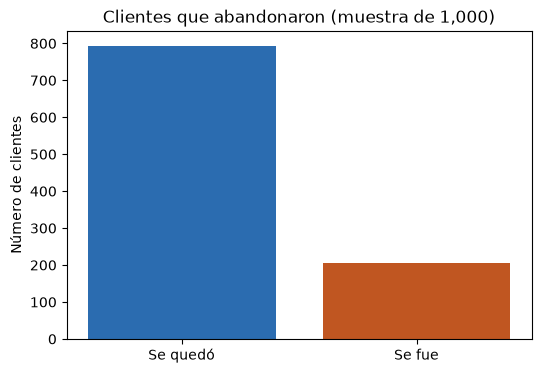

In [13]:
etiquetas_abandono = ["Se quedó", "Se fue"]
alturas_abandono = [frecuencia_abandono[0], frecuencia_abandono[1]]
figura, eje = plt.subplots(figsize=(6, 4))
eje.bar(etiquetas_abandono, alturas_abandono, color=["#2b6cb0", "#c05621"])
eje.set_ylabel("Número de clientes")
eje.set_title("Clientes que abandonaron (muestra de 1,000)")
plt.show()

**Qué aporta:** muestra el tamaño del problema. Unos 2 de cada 10 clientes abandonaron. También muestra que hay muchos más clientes que se quedan que clientes que se van.

### Gráfica B · Barras: porcentaje de abandono por actividad

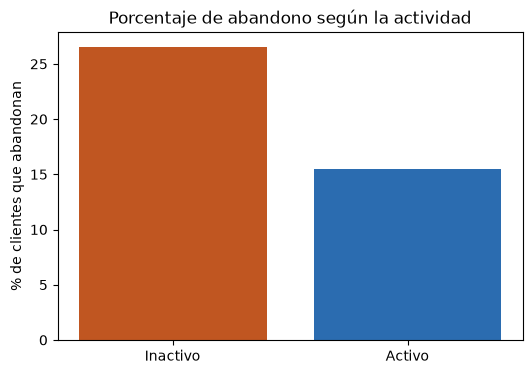

In [14]:
etiquetas_actividad = ["Inactivo", "Activo"]
alturas_actividad = [porcentaje_por_fila.loc[0, 1], porcentaje_por_fila.loc[1, 1]]
figura, eje = plt.subplots(figsize=(6, 4))
eje.bar(etiquetas_actividad, alturas_actividad, color=["#c05621", "#2b6cb0"])
eje.set_ylabel("% de clientes que abandonan")
eje.set_title("Porcentaje de abandono según la actividad")
plt.show()

**Qué aporta:** compara el porcentaje de abandono entre inactivos (26.6 %) y activos (15.5 %). Es la diferencia que se estudia en la pregunta P3.

**Por qué porcentajes y no frecuencias:** los dos grupos tienen distinto tamaño (463 y 537). Comparar cantidades sería injusto; comparar porcentajes no.

### Gráfica C · Histograma: el saldo de quienes abandonan

Un **histograma** divide los valores de una variable cuantitativa en intervalos y muestra cuántos datos caen en cada uno. Sirve para ver la **forma** de los datos.

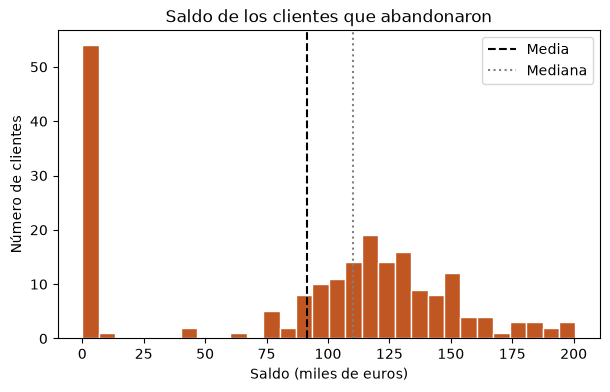

In [15]:
saldo_abandona = muestra.loc[muestra["abandono"] == 1, "saldo"]
figura, eje = plt.subplots(figsize=(7, 4))
eje.hist(saldo_abandona / 1000, bins=30, color="#c05621", edgecolor="white")
eje.axvline(saldo_abandona.mean() / 1000, color="black", linestyle="--", label="Media")
eje.axvline(saldo_abandona.median() / 1000, color="gray", linestyle=":", label="Mediana")
eje.set_xlabel("Saldo (miles de euros)")
eje.set_ylabel("Número de clientes")
eje.set_title("Saldo de los clientes que abandonaron")
eje.legend()
plt.show()

**Qué aporta:** el saldo forma **dos grupos**: una barra alta en 0 (cuentas sin dinero) y otro grupo de clientes con saldos entre unos 75 y 200 mil euros. Los datos **no tienen forma de campana**. Esto importa en el Día 4, porque la fórmula del intervalo para una media usa la forma de campana; ahí se explica por qué aun así se puede usar.

### Gráfica D · Diagrama de caja: la edad según el abandono

Un **diagrama de caja** resume una variable cuantitativa en cinco partes:
- La **línea dentro de la caja** es la mediana.
- La **caja** contiene al 50 % de los clientes que están en el centro (del 25 % al 75 % de los datos ordenados).
- Las **líneas que salen de la caja** llegan hasta los valores más alejados que no se consideran atípicos.
- Los **círculos** son valores atípicos: muy alejados del resto.

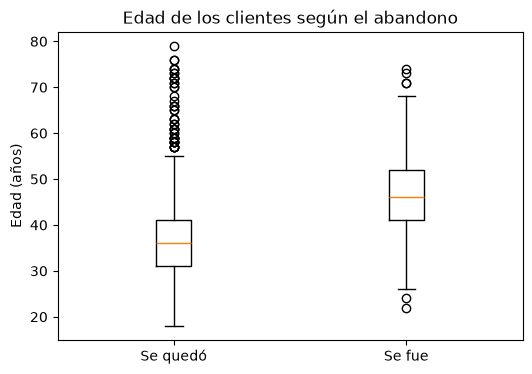

Mediana de edad de quienes se quedaron: 36.0
Mediana de edad de quienes se fueron: 46.0


In [16]:
edad_se_queda = muestra.loc[muestra["abandono"] == 0, "edad"]
edad_se_va = muestra.loc[muestra["abandono"] == 1, "edad"]
figura, eje = plt.subplots(figsize=(6, 4))
eje.boxplot([edad_se_queda, edad_se_va], tick_labels=["Se quedó", "Se fue"])
eje.set_ylabel("Edad (años)")
eje.set_title("Edad de los clientes según el abandono")
plt.show()
print("Mediana de edad de quienes se quedaron:", edad_se_queda.median())
print("Mediana de edad de quienes se fueron:", edad_se_va.median())

**Qué aporta:** la caja de quienes se fueron está más arriba: su mediana es 46 años contra 36 de quienes se quedaron. Los clientes que abandonan tienden a ser mayores. Es la diferencia que se estudia en la pregunta P4. Las cajas se enciman en parte: hay clientes jóvenes que se van y mayores que se quedan; la edad es una tendencia, no una regla.

---
## Preguntas que puede hacer el profesor (apartado 3)

**1. ¿De dónde salieron sus datos?**
De un dataset público de Kaggle llamado *Churn Modelling*, con 10,000 clientes de un banco en Francia, Alemania y España. Lo revisamos con 12 reglas de calidad y seleccionamos 1,000 clientes por sorteo.

**2. ¿Por qué no recolectaron sus propios datos?**
Los datos de clientes de un banco son confidenciales y no se pueden obtener con una encuesta. Un dataset público y anonimizado permite estudiar el problema real y que cualquiera reproduzca el análisis.

**3. ¿Qué diferencia hay entre la media y la mediana?**
La media es la suma dividida entre el número de datos. La mediana es el valor del centro al ordenar los datos. Los valores extremos afectan a la media pero casi no a la mediana.

**4. ¿Por qué en el saldo la mediana es mayor que la media?**
Porque el 37.5 % de los clientes de la muestra tiene saldo 0. Esos ceros bajan la media; la mediana queda en el centro de los clientes ordenados, que ya está entre los que tienen saldo.

**5. ¿Qué significa una desviación estándar de 10.5 años en la edad?**
Que la edad de un cliente típico se aleja unos 10.5 años de la media de 39 años.

**6. ¿Por qué comparan porcentajes y no cantidades entre inactivos y activos?**
Porque los grupos tienen distinto tamaño (463 y 537). El porcentaje permite comparar grupos de tamaño diferente.

**7. ¿Qué aporta el histograma del saldo?**
Muestra que el saldo forma dos grupos (ceros y saldos altos) y que no tiene forma de campana. Eso obliga a justificar el intervalo de la media en el Día 4.

**8. ¿Cómo se lee el diagrama de caja?**
La línea del centro es la mediana; la caja contiene al 50 % central de los clientes; los círculos son valores atípicos. La caja de quienes se van está más arriba: son mayores.

**9. ¿Ya con estas gráficas pueden decir que los inactivos se van más?**
En la muestra, sí. Para afirmarlo de los 10,000 clientes se necesita un intervalo de confianza (Día 4).

---
## Tarea del Día 2 (para todo el equipo)

Cada integrante elige una de las gráficas A, B, C o D y explica en voz alta, sin leer: qué tipo de gráfica es, cómo se lee y qué información aporta al proyecto.

➡️ **Día 3:** Apartado 4 (estimación puntual) y el primer intervalo de confianza.